# Lab 3: Robot Control

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LxViRaL-teaching/medical-robotics-2026/blob/main/week-3/control_lab.ipynb)

In this lab you control the motion of robots using feedback: This is done in a loop that reads the sensors, computes a torque for each motor, and sends it, hundreds of times per second.
Besides this notebook there are three auxiliary files:

| File | What it is |
|---|---|
| `pendulum.urdf` | The motorised pendulum. The angle is 0 when it hangs straight down. Its masses are listed at the top of the file. |
| `arm_2r.urdf` | A planar 2-link arm with a 4 kg payload at the tip. |
| `ctrl_utils.py` | Helpers to load robots and draw plots. You do not need to edit it. |

First, let's check the environment and do the relevant imports:

In [1]:
import os, sys, time, urllib.request

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pybullet"], check=True)
    RAW = "https://raw.githubusercontent.com/LxViRaL-teaching/medical-robotics-2026/main/week-3/"
    for f in ["ctrl_utils.py", "pendulum.urdf", "arm_2r.urdf"]:
        if not os.path.exists(f):
            urllib.request.urlretrieve(RAW + f, f)

import numpy as np
import pybullet as p
import ctrl_utils as ctl

DT = ctl.DT   # time step of the simulation, and of our controller: 1/240 s

## 1. The pendulum

`ctl.load_robot` loads the robot with its default motor controllers switched off: from now on, the only torque on the joint is the one you send.

In [2]:
ctl.connect()
pendulum = ctl.load_robot("pendulum.urdf")
motor = ctl.joint_index(pendulum, "motor_joint")
ball = ctl.link_index(pendulum, "ball_link")

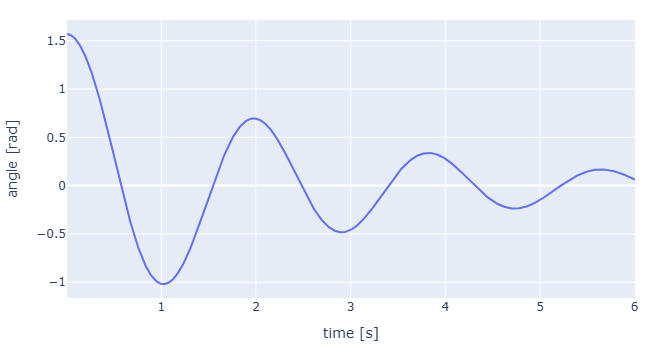

In [3]:
ctl.reset_joints(pendulum, [motor], [np.pi/2])
t = 0.0
duration = 6.0
time_log, angle_log, torque_log = [], [], []

p.enableJointForceTorqueSensor(pendulum,motor,1)
while t < duration:

    p.stepSimulation()
    q,qd,tau,_ = p.getJointState(pendulum, motor)

    t = t + DT
    time.sleep(DT)

    # Logging:
    time_log.append(t)
    angle_log.append(q)

ctl.plot_series(time_log, {"Joint Position": angle_log}, ylabel="angle [rad]")

### 1.1 Proportional control

The goal is to lift the arm to the horizontal, $q_{desired} = \pi/2$. We set motor torque to be proportional to the current error:

$$\tau = K_p\,(q_{desired} - q)$$

> **T1.** Find a reasonable value for $K_p$ and implement a P control law

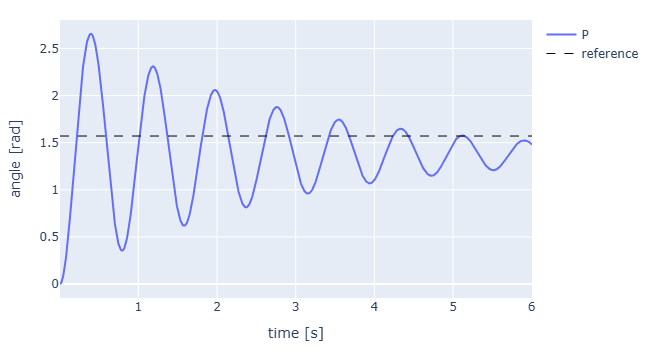

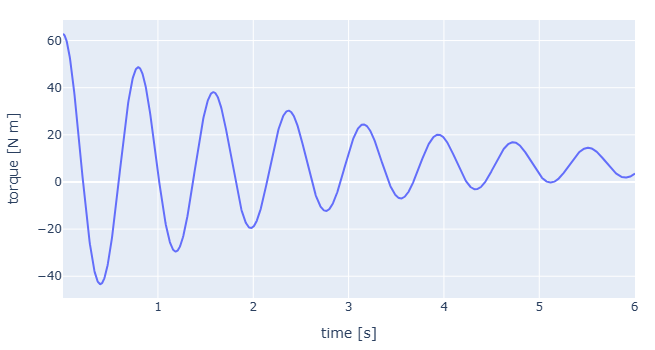

In [20]:
# Controller settings
q_desired = np.pi / 2    # target angle [rad]: arm horizontal
#TODO: 
Kp = 40.0                # proportional gain [N m per rad of error]
duration = 6.0           # how long to run [s]

# Start with the arm hanging down, at rest
ctl.reset_joints(pendulum, [motor], [0.0])

time_log, angle_log, torque_log = [], [], []
t = 0.0
while t < duration:
    # 1. SENSE: read the joint angle from the encoder
    q = p.getJointState(pendulum, motor)[0]

    # 2. CONTROL: compute the motor torque from the error
    #TODO error
    error = q_desired - q
    
    #TODO torque = 
    torque = (error * Kp)


    # 3. ACT: send the torque to the motor, and let the simulated world move for one time step
    p.setJointMotorControl2(pendulum, motor, p.TORQUE_CONTROL, force=torque)

    
    # 4. WAIT: let one time step of real time pass, so what you see runs at real speed (comment out for faster simulation, or sleep for DT/4)
    p.stepSimulation()
    t = t + DT
    
    time.sleep(DT)

    # Logging:
    time_log.append(t)
    angle_log.append(q)
    torque_log.append(torque)

p_time, p_angle, p_torque = time_log, angle_log, torque_log   # keep this run, to compare later
ctl.plot_series(time_log, {"P": angle_log}, ylabel="angle [rad]", ref=q_desired)
ctl.plot_series(time_log, {"P": torque_log}, ylabel="torque [N m]")

> **Q1.** The arm stops below the target. When it is at rest, which two torques must balance? Use that to explain the remaining error, and what happens to it if you increase $K_p$.

**Answer Q1.**: At rest, the torque applied by the engine is simetrical to the force of the mass of the pendulum
(inserir maneira mais cientifica)

### 1.2 PID control

Two more terms, both computed from the error:

- **integral**: the sum of all past errors, each multiplied by the time step;
- **derivative**: how fast the error is changing, from the difference between this error and the previous one.

$$\tau = K_p\, e_k + K_i \sum_{j \le k} e_j\,\Delta t + K_d\, \frac{e_k - e_{k-1}}{\Delta t}$$

> **T2.** Implement the PID control law, then run the cell with $K_i = 0$ first (PD), then with $K_i \neq 0$ (PID). 

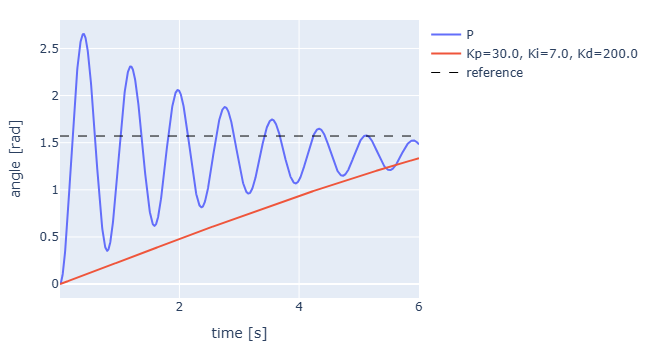

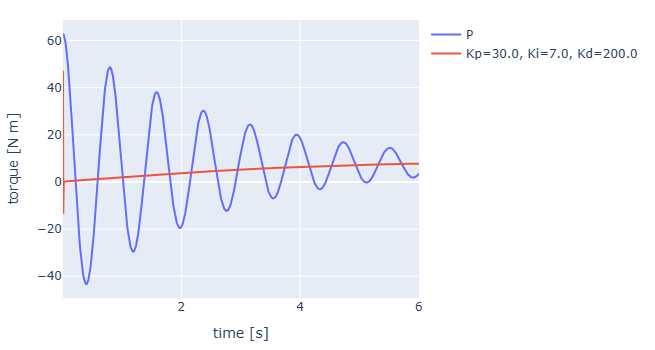

In [40]:
#TODO: 
Kp = 30.0

#TODO: 
Ki = 7.0

#TODO: 
Kd = 200.0

duration = 6.0

ctl.reset_joints(pendulum, [motor], [0.0])

error_sum = 0.0                  # for the integral term
error_previous = q_desired - 0.0 # for the derivative term (error at the start)

time_log, angle_log, torque_log = [], [], []
t = 0.0
while t < duration:
    # 1. SENSE
    q = p.getJointState(pendulum, motor)[0]

    # 2. CONTROL
    #TODO: 
    error = q_desired - q
    
    #TODO: 
    error_sum = error_sum + error * DT
    
    #TODO: 
    error_rate = (error - error_previous)/DT
    
    #TODO: 
    torque = (Kp * error) + (Ki * error_sum) + (Kd * error_rate)

    error_previous = error #save for next iteration
    # 3. ACT
    p.setJointMotorControl2(pendulum, motor, p.TORQUE_CONTROL, force=torque)
    p.stepSimulation()
    t = t + DT

    # 4. WAIT
    time.sleep(DT)

    time_log.append(t)
    angle_log.append(q)
    torque_log.append(torque)

label = f"Kp={Kp}, Ki={Ki}, Kd={Kd}"
ctl.plot_series(time_log, {"P": p_angle, label: angle_log}, ylabel="angle [rad]", ref=q_desired)
ctl.plot_series(time_log, {"P": p_torque, label: torque_log}, ylabel="torque [N m]")

**Q2.** What does each term change in the response: overshoot, time to settle, final error? Why does the integral term remove the final error, and what does it cost?

**Q3.** What happens to the torque when $K_d$ is very large? Look at the torque plot.

**Answer Q2.** 

**Answer Q3.** gets very slow and doesn'g get to the position


Let's implement the reusable `PID` class

In [ ]:
class PID:
    def __init__(self, Kp, Ki, Kd, dt):
        self.Kp, self.Ki, self.Kd, self.dt = Kp, Ki, Kd, dt
        self.clear()
        
    def clear(self):
        self.error_sum = 0.0
        self.error_previous = None        # no derivative kick on the first step

    def step(self, error):
        if self.error_previous is None:
            self.error_previous = error
        
        #TODO: self.error_sum = 
        #TODO: error_rate = 
        #TODO: control = 

        self.error_previous = error
        return control

### 1.3 A heavy payload, and gravity compensation

The torque that gravity applies on the pendulum depends on the angle and on the masses:

$$\tau_{gravity}(q) = g\,\left(m_{arm}\,\frac{L}{2} + m_{ball}\,L\right)\sin q$$

Helper functions `get_length()`and `get_mass()` give us the robot parameters.

**T3.** write this function, and compare it with the torque PyBullet computes to hold the pendulum still at a few angles. 

In [ ]:
L = ctl.get_length(pendulum,"ball_link")
m_ball = ctl.get_mass(pendulum,"ball_link")
m_arm = ctl.get_mass(pendulum,"arm_link")

def gravity_torque(q, m_ball):
    #TODO: gravity = 
    return gravity

for q in [0.3, 1.2, 2.5]:
    pybullet_torque = p.calculateInverseDynamics(pendulum, [q], [0.0], [0.0])[0]
    ctl.check(f"q = {q} rad", gravity_torque(q, m_ball), pybullet_torque)

Now the pendulum carries 10 kg. Run your PID again, with the same gains.

In [ ]:
ctl.change_mass(pendulum, "ball_link", 10.0)

#TODO: pid = PID(Kp=0.0, Ki=0.0, Kd=0.0, dt=DT)   # same gains as before, new controller (empty integral)
duration = 10.0

ctl.reset_joints(pendulum, [motor], [0.0])

time_log, angle_log = [], []
t = 0.0
while t < duration:
    q = p.getJointState(pendulum, motor)[0]

    torque = pid.step(q_desired - q)

    p.setJointMotorControl2(pendulum, motor, p.TORQUE_CONTROL, force=torque)
    p.stepSimulation()
    t = t + DT
    time.sleep(DT/10)

    time_log.append(t)
    angle_log.append(q)

heavy_time, heavy_angle = time_log, angle_log
ctl.plot_series(time_log, {"PID, 10 kg": angle_log}, ylabel="angle [rad]", ref=q_desired)

If we know the gravity torque, we can add it to the command. Then the PID only has to correct what the model gets wrong.

$$\tau = \tau_{PID} + \tau_{gravity}(q)$$

In [ ]:
m_ball_model = 10.0
pid = PID(Kp=300.0, Ki=150.0, Kd=30.0, dt=DT)

ctl.reset_joints(pendulum, [motor], [0.0])

time_log, gc_angle = [], []
t = 0.0
while t < duration:
    q = p.getJointState(pendulum, motor)[0]

    torque = pid.step(q_desired - q) + gravity_torque(q, m_ball_model)   # feedback + model

    p.setJointMotorControl2(pendulum, motor, p.TORQUE_CONTROL, force=torque)
    p.stepSimulation()
    t = t + DT
    time.sleep(DT)

    time_log.append(t)
    gc_angle.append(q)

ctl.plot_series(time_log, {"PID": heavy_angle, f"PID + gravity (model: {m_ball_model} kg)": gc_angle},
                ylabel="angle [rad]", ref=q_desired)

**Q4.** Why does the plain PID struggle with 10 kg, when the same gains worked with 2 kg?

**T4.** Set `m_ball_model = 8.0` (the model is wrong) and run again, first with `Ki = 0` and then with the original `Ki`. Explain what you see.

**Answer Q4.**:

**Answer T4.**:

## 2. A 2-link arm

Now we have two joints, `shoulder_joint` and `elbow_joint`, with a payload at the tip.
The tip must go around a **triangle** in the plane of the arm.

The controller works on the joints, so first we turn the path of the tip into a path of the joints:

1. the desired tip position at every time step (`ctl.create_triangle_traj`);
2. inverse kinematics at every time step, each search starting from the previous solution;
3. joint velocities and accelerations, by differentiating the joint path.

In [ ]:
ctl.connect(camera_target=(0.5, -0.3, 1.0), camera_distance=2.5)
arm = ctl.load_robot("arm_2r.urdf")
arm_joints, joint_names = ctl.moving_joints(arm)
arm_tip = ctl.link_index(arm, "tip_link")

# 1. Desired tip positions: two laps of 4 s around a triangle in the plane of the arm (y = -0.35 m)
corners = [[0.5, -0.35, 1.0], [0.9, -0.35, 1.0], [0.7, -0.35, 1.5]]
times, tip_desired = ctl.create_triangle_traj(corners, lap_time=4.0, laps=2)

In [ ]:
# 2. Inverse kinematics. We start the search from the previous solution before each call.
q_guess = [1.0, 1.0]
q_path = []
for position in tip_desired:
    ctl.reset_joints(arm, arm_joints, q_guess)
    q_guess = p.calculateInverseKinematics(arm, arm_tip, list(position))
    q_path.append(q_guess)
q_path = np.array(q_path)

# 3. Joint velocities and accelerations
qd_path = np.gradient(q_path, DT, axis=0)
qdd_path = np.gradient(qd_path, DT, axis=0)

ctl.draw_polyline(corners + corners[:1], color=(0, 0, 0))
ctl.plot_joints(times, {"desired": q_path}, joint_names=joint_names)

### 2.1 PID on each joint

The same PID as for the pendulum, now with one error per joint (NumPy arrays instead of numbers).
We also record where the tip goes.

In [ ]:
# The same PID class, with one gain per joint
pid = PID(Kp=np.array([400.0, 150.0]), Ki=np.array([100.0, 50.0]), Kd=np.array([40.0, 12.0]), dt=DT)

ctl.reset_joints(arm, arm_joints, q_path[0])

angle_log, torque_log, tip_log = [], [], []
for k in range(len(times)):
    states = p.getJointStates(arm, arm_joints)
    q = np.array([states[0][0], states[1][0]])

    torque = pid.step(q_path[k] - q)

    p.setJointMotorControlArray(arm, arm_joints, p.TORQUE_CONTROL, forces=list(torque))
    p.stepSimulation()
    time.sleep(DT)

    angle_log.append(q)
    torque_log.append(torque)
    tip_log.append(p.getLinkState(arm, arm_tip)[4])

pid_angle, pid_torque, pid_tip = np.array(angle_log), np.array(torque_log), np.array(tip_log)
ctl.draw_polyline(pid_tip, color=(0, 0, 1), every=10)
ctl.plot_joints(times, {"PID": pid_angle}, ref=q_path, joint_names=joint_names)

For two joints, the equation of motion is a matrix equation:

$$M(q)\,\ddot q + C(q,\dot q)\,\dot q + g(q) = \tau$$

$M(q)$, the inertia matrix, changes with the configuration. Look at it with the elbow stretched and folded:

In [ ]:
for elbow in [0.0, np.pi / 2, 2.5]:
    M = p.calculateMassMatrix(arm, [np.pi / 2, elbow])
    print(f"elbow at {elbow:.2f} rad:\n{np.array(M)}\n")

**Q6.** Where along the triangle is the PID error largest? Use $M(q)$ to explain why the same gains do not work equally well in every configuration.

**Q7.** At the corners the tip must change direction instantly. What does that mean for the joint accelerations? Plot `qdd_path`.

**Answer Q6.**:

**Answer Q7.**:

### 2.2 Computed torque

Instead of a torque, we choose the **acceleration** we want each joint to have, and ask the model which torque produces it:

$$\ddot q_{command} = \ddot q_{desired} + K_d\,(\dot q_{desired} - \dot q) + K_p\,(q_{desired} - q)$$

$$\tau = M(q)\,\ddot q_{command} + C(q,\dot q)\,\dot q + g(q)$$

PyBullet computes the second line for us: `p.calculateInverseDynamics(robot, q, qd, qdd_command)`.
If the model is exact, the error of each joint behaves like a mass-spring-damper, $\ddot e + K_d\,\dot e + K_p\,e = 0$, in every configuration. We choose its natural frequency $\omega_n$ and damping ratio $\zeta$: $K_p = \omega_n^2$, $K_d = 2\zeta\omega_n$.

The controller needs the joint velocities, so we need to read them too.

In [ ]:
wn = 10.0     # natural frequency of the error [rad/s]
zeta = 1.0    # damping ratio
Kp = wn ** 2
Kd = 2 * zeta * wn

ctl.reset_joints(arm, arm_joints, q_path[0])

angle_log, torque_log, tip_log = [], [], []
for k in range(len(times)):
    states = p.getJointStates(arm, arm_joints)
    q = np.array([states[0][0], states[1][0]])
    qd = np.array([states[0][1], states[1][1]])

    qdd_command = qdd_path[k] + Kd * (qd_path[k] - qd) + Kp * (q_path[k] - q)
    torque = p.calculateInverseDynamics(arm, list(q), list(qd), list(qdd_command))

    p.setJointMotorControlArray(arm, arm_joints, p.TORQUE_CONTROL, forces=list(torque))
    p.stepSimulation()
    time.sleep(DT)

    angle_log.append(q)
    torque_log.append(torque)
    tip_log.append(p.getLinkState(arm, arm_tip)[4])

ct_angle, ct_torque, ct_tip = np.array(angle_log), np.array(torque_log), np.array(tip_log)

In [ ]:
ctl.draw_polyline(ct_tip, color=(1, 0, 0), every=10)

ctl.plot_joints(times, {"PID": pid_angle, "computed torque":  ct_angle},
                joint_names=joint_names, ylabel="angle [rad]", ref=q_path)

ctl.plot_path2d({"PID": pid_tip, "computed torque": ct_tip}, ref=tip_desired)
ctl.plot_joints(times, {"PID": q_path - pid_angle, "computed torque": q_path - ct_angle},
                joint_names=joint_names, ylabel="error [rad]")
ctl.plot_joints(times, {"PID": pid_torque, "computed torque": ct_torque},
                joint_names=joint_names, ylabel="torque [N m]")

**Q8.** Where does computed torque still make an error? Think about the corners, and about what the model ignores (look at `<dynamics>` in `arm_2r.urdf`).

**Q9.** Try other values of $\omega_n$ and $\zeta$. What would limit $\omega_n$ on a real robot?

**Answer Q8.** 

**Answer Q9.** 

## 3. Franka FR3: bringing kinematics and control together

The same steps on a 7-joint robot. The tool tip must follow a **descending helix** (two turns) that starts where the tip is, keeping the tool pointing down.

In [ ]:
ctl.connect(camera_target=(0.5, 0, 0.35), camera_distance=1.6, yaw=50, pitch=-25)
panda = ctl.load_robot("franka_panda/panda.urdf")
panda_joints, panda_joint_names = ctl.moving_joints(panda)   # 7 arm joints + 2 fingers
tip = ctl.link_index(panda, "panda_grasptarget")

# Initial configuration, tool pointing down
q_home = [0.0, -0.3, 0.0, -2.2, 0.0, 1.9, 0.785, 0.02, 0.02]
ctl.reset_joints(panda, panda_joints, q_home)
tip_state = p.getLinkState(panda, tip, computeForwardKinematics=True)
tip_start = tip_state[4]         # position [m]
tip_orientation = tip_state[5]   # orientation (quaternion), kept constant along the path

# 1. Desired tip positions: a helix starting at the tip, radius 0.1 m, going down 0.25 m in 6 s
times, tip_desired = ctl.create_3d_helix(tip_start, radius=0.1, depth=0.25, turns=2, duration=6.0)

# 2. Inverse kinematics, each search starting from the previous solution
q_guess = q_home
q_path = []
for position in tip_desired:
    ctl.reset_joints(panda, panda_joints, q_guess)
    q_guess = p.calculateInverseKinematics(panda, tip, list(position), tip_orientation)
    q_path.append(q_guess)
q_path = np.array(q_path)

# 3. Joint velocities and accelerations
qd_path = np.gradient(q_path, DT, axis=0)
qdd_path = np.gradient(qd_path, DT, axis=0)

ctl.draw_polyline(tip_desired, every=10)

**PD + gravity compensation**: $\tau = K_p\,(q_{desired} - q) + K_d\,(\dot q_{desired} - \dot q) + g(q)$, where $g(q)$ is inverse dynamics with zero velocity and acceleration.

In [ ]:
Kp, Kd = 300.0, 30.0
zeros = [0.0] * len(panda_joints)

ctl.reset_joints(panda, panda_joints, q_path[0])
pd_tip = []
for k in range(len(times)):
    states = p.getJointStates(panda, panda_joints)
    q = np.array([state[0] for state in states])
    qd = np.array([state[1] for state in states])

    gravity = np.array(p.calculateInverseDynamics(panda, list(q), zeros, zeros))
    torque = Kp * (q_path[k] - q) + Kd * (qd_path[k] - qd) + gravity

    p.setJointMotorControlArray(panda, panda_joints, p.TORQUE_CONTROL, forces=list(torque))
    p.stepSimulation()
    time.sleep(DT)

    pd_tip.append(p.getLinkState(panda, tip)[4])

pd_tip = np.array(pd_tip)
ctl.draw_polyline(pd_tip, color=(0, 0, 1), every=10)

**Computed torque**, exactly as for the 2-link arm.

In [ ]:
wn, zeta = 20.0, 1.0
Kp, Kd = wn ** 2, 2 * zeta * wn

ctl.reset_joints(panda, panda_joints, q_path[0])
ct_tip = []
for k in range(len(times)):
    states = p.getJointStates(panda, panda_joints)
    q = np.array([state[0] for state in states])
    qd = np.array([state[1] for state in states])

    qdd_command = qdd_path[k] + Kd * (qd_path[k] - qd) + Kp * (q_path[k] - q)
    torque = p.calculateInverseDynamics(panda, list(q), list(qd), list(qdd_command))

    p.setJointMotorControlArray(panda, panda_joints, p.TORQUE_CONTROL, forces=list(torque))
    p.stepSimulation()
    time.sleep(DT)

    ct_tip.append(p.getLinkState(panda, tip)[4])

ct_tip = np.array(ct_tip)
ctl.draw_polyline(ct_tip, color=(1, 0, 0), every=10)

In [ ]:
ctl.plot_path3d({"PD + gravity": pd_tip, "computed torque": ct_tip}, ref=tip_desired)

pd_error = 1000 * np.linalg.norm(pd_tip - tip_desired, axis=1)   # [mm]
ct_error = 1000 * np.linalg.norm(ct_tip - tip_desired, axis=1)
ctl.plot_series(times, {"PD + gravity": pd_error, "computed torque": ct_error}, ylabel="tip error [mm]")

**Q10.** Where along the helix is the PD error largest, and why there?

**Q11.** Make the helix twice as fast (`duration=3.0`). Which controller suffers more, and why?

**Answer Q10.**: 

**Answer Q11.**:

In [ ]:
p.disconnect()